In [2]:
import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

GPU available: True
GPU name: Tesla T4


In [3]:
import sys
import time
import platform
import statistics
import torch
import pandas as pd
import matplotlib.pyplot as plt

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("CPU environment:", platform.platform())
print("Logical CPU threads available:", torch.get_num_threads())
print("CUDA available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError("No CUDA GPU detected. In Colab: Runtime → Change runtime type → GPU, then rerun this cell.")
print("GPU:", torch.cuda.get_device_name(0))

# For more comparable float32 numerical precision, avoid TF32 shortcuts.
torch.set_float32_matmul_precision("highest")
torch.manual_seed(42)

Python: 3.13.16
PyTorch: 2.11.0+cu130
CPU environment: Linux-6.6.159+-x86_64-with-glibc2.39
Logical CPU threads available: 1
CUDA available: True
GPU: Tesla T4


In [4]:
# Sizes are small enough to be reasonable on common Colab runtimes.
SIZES = [64, 256, 1024, 2048]
OPERATIONS_PER_TRIAL = {64: 100, 256: 40, 1024: 8, 2048: 3}
TRIALS = 7
WARMUPS = 3


def benchmark_ms(fn, *, cuda=False, operations=10, trials=7, warmups=3):
    # Initialize runtime, kernels, and caches before measuring.
    for _ in range(warmups):
        fn()
    if cuda:
        torch.cuda.synchronize()

    sample_times = []
    for _ in range(trials):
        if cuda:
            torch.cuda.synchronize()
        start = time.perf_counter()
        for _ in range(operations):
            fn()
        if cuda:
            torch.cuda.synchronize()  # Wait for queued GPU computation to finish.
        sample_times.append((time.perf_counter() - start) * 1000 / operations)
    return statistics.median(sample_times)


records = []
for size in SIZES:
    x_cpu = torch.randn(size, size, dtype=torch.float32)
    y_cpu = torch.randn(size, size, dtype=torch.float32)
    x_gpu = x_cpu.to("cuda")
    y_gpu = y_cpu.to("cuda")

    # Identical mathematical operation; inputs pre-positioned on their devices.
    cpu_fn = lambda: x_cpu @ y_cpu
    gpu_fn = lambda: x_gpu @ y_gpu

    # Practical scenario: both inputs begin on the CPU; final output needed on CPU.
    def gpu_end_to_end():
        a = x_cpu.to("cuda")
        b = y_cpu.to("cuda")
        result = a @ b
        return result.to("cpu")

    ops = OPERATIONS_PER_TRIAL[size]
    cpu_ms = benchmark_ms(cpu_fn, operations=ops, trials=TRIALS, warmups=WARMUPS)
    gpu_ms = benchmark_ms(gpu_fn, cuda=True, operations=ops, trials=TRIALS, warmups=WARMUPS)
    gpu_total_ms = benchmark_ms(gpu_end_to_end, cuda=True, operations=ops,
                                trials=TRIALS, warmups=WARMUPS)

    records.append({
        "Matrix size": f"{size} × {size}",
        "CPU compute (ms)": cpu_ms,
        "GPU compute (ms)": gpu_ms,
        "GPU + transfers (ms)": gpu_total_ms,
        "GPU compute speedup": cpu_ms / gpu_ms,
        "GPU e2e speedup": cpu_ms / gpu_total_ms,
    })
    print(f"Finished {size} × {size}")

results = pd.DataFrame(records)
display(results.round(3))

Finished 64 × 64
Finished 256 × 256
Finished 1024 × 1024
Finished 2048 × 2048


,Matrix size,CPU compute (ms),GPU compute (ms),GPU + transfers (ms),GPU compute speedup,GPU e2e speedup
0,64 × 64,0.009,0.016,0.085,0.592,0.109
1,256 × 256,0.295,0.042,0.355,7.113,0.831
2,1024 × 1024,16.974,0.835,3.820,20.335,4.444
3,2048 × 2048,141.609,6.066,14.689,23.345,9.640


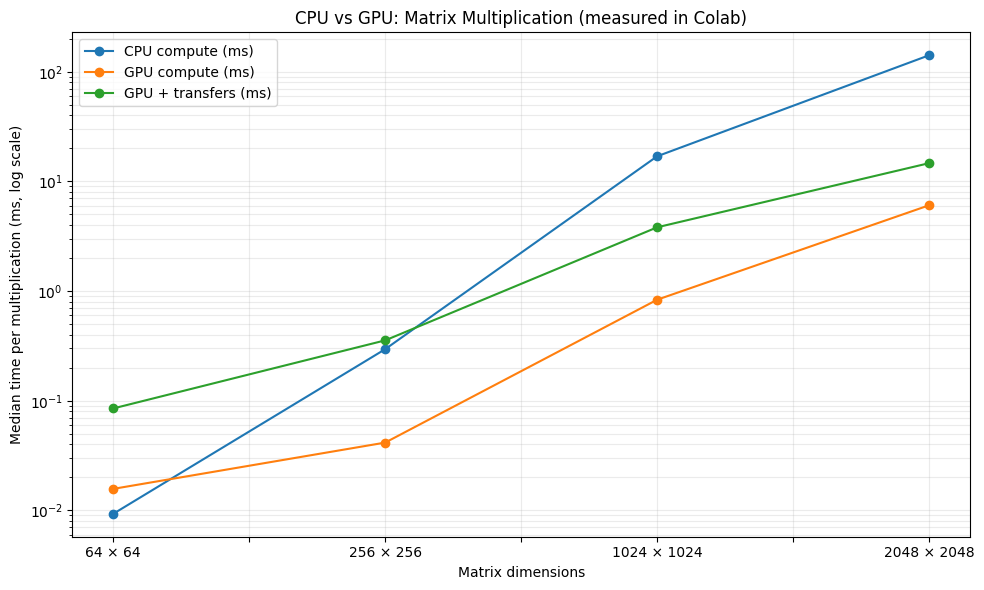

Chart saved as cpu_gpu_benchmark.png


In [5]:
ax = results.plot(
    x="Matrix size",
    y=["CPU compute (ms)", "GPU compute (ms)", "GPU + transfers (ms)"],
    kind="line", marker="o", figsize=(10, 6),
)
ax.set_title("CPU vs GPU: Matrix Multiplication (measured in Colab)")
ax.set_xlabel("Matrix dimensions")
ax.set_ylabel("Median time per multiplication (ms, log scale)")
ax.set_yscale("log")
ax.grid(True, which="both", alpha=0.25)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("cpu_gpu_benchmark.png", dpi=180, bbox_inches="tight")
plt.show()
print("Chart saved as cpu_gpu_benchmark.png")

In [6]:
for _, r in results.iterrows():
    pure = ("GPU" if r["GPU compute speedup"] > 1 else "CPU")
    end = ("GPU" if r["GPU e2e speedup"] > 1 else "CPU")
    print(f'{r["Matrix size"]}: compute-only winner = {pure} '
          f'({r["GPU compute speedup"]:.2f}× CPU/GPU ratio); '
          f'with transfers winner = {end} '
          f'({r["GPU e2e speedup"]:.2f}× CPU/GPU ratio).')

print("\nThink about:")
print("1. Where does GPU compute start beating CPU compute, if anywhere?")
print("2. How does including transfers change that result?")
print("3. Are your measurements stable if you rerun the notebook?")
print("4. What are your exact CPU, GPU, PyTorch version, and runtime settings?")

64 × 64: compute-only winner = CPU (0.59× CPU/GPU ratio); with transfers winner = CPU (0.11× CPU/GPU ratio).
256 × 256: compute-only winner = GPU (7.11× CPU/GPU ratio); with transfers winner = CPU (0.83× CPU/GPU ratio).
1024 × 1024: compute-only winner = GPU (20.33× CPU/GPU ratio); with transfers winner = GPU (4.44× CPU/GPU ratio).
2048 × 2048: compute-only winner = GPU (23.35× CPU/GPU ratio); with transfers winner = GPU (9.64× CPU/GPU ratio).

Think about:
1. Where does GPU compute start beating CPU compute, if anywhere?
2. How does including transfers change that result?
3. Are your measurements stable if you rerun the notebook?
4. What are your exact CPU, GPU, PyTorch version, and runtime settings?
